# Indicadores de gestion de eventos

Los tres indicadores ya se ejecutaron mediante scripts contra MongoDB. Este notebook reproduce el analisis.
Sus salidas se generan al ejecutar las celdas; no contiene resultados precargados.
Solo lecturas de MongoDB y exportaciones locales. Cada indicador toma su propia instantanea snapshot.
Comprobar que no hubo escrituras entre cortes antes de comparar los resultados.


In [1]:
from pathlib import Path
import os
from dotenv import load_dotenv
from pymongo import MongoClient

candidatas = [Path.cwd(), *Path.cwd().parents]
raiz = next((p for p in candidatas if (p / "docker-compose.yml").exists()), None)
if raiz is None:
    raise RuntimeError("Abrir Jupyter desde el proyecto o su carpeta analisis.")
load_dotenv(raiz / ".env")
uri = os.getenv("MONGO_URI", "mongodb://localhost:27018/?replicaSet=rs0&directConnection=true")
nombre_base = os.getenv("MONGO_DB", "gestion_eventos")
cliente = MongoClient(uri, tz_aware=True, serverSelectionTimeoutMS=5000)
base = cliente[nombre_base]
base.command("ping")
print("Conexion OK:", nombre_base)  # No imprimir URI: puede contener credenciales.


Conexion OK: gestion_eventos


## Corte del analisis

Registrar la fecha real de ejecucion, los totales y la inclusion/exclusion de la demo.
No copiar resultados de otra fecha como si fueran obtenidos aqui.


In [2]:
# Conteos de solo lectura; se completan al ejecutar esta celda.
from datetime import datetime, timezone
corte = {"fecha_utc": datetime.now(timezone.utc).isoformat(),
         "eventos": base.eventos.count_documents({}),
         "inscripciones": base.inscripciones.count_documents({})}
corte


{'fecha_utc': '2026-10-29T21:46:45.463230+00:00',
 'eventos': 22,
 'inscripciones': 201}

## I1. Demanda por actividad

Implementado: tabla completa, grafico de barras e interpretacion. Solo inscripciones confirmadas; agrupacion por evento y codigo.

La celda toma su propia instantanea consistente (corte_i1), exporta a una carpeta nueva y muestra los resultados. No modifica MongoDB.
El grafico incluye todos los estados de evento y solo grupos con demanda positiva.


,evento_id,evento,estado_evento,codigo_actividad,actividad,selecciones_confirmadas
0,720000000000000000000003,Emprendimientos 3,publicado,ACT-01,Emprendimientos práctico,8
1,720000000000000000000012,Desarrollo web 12,publicado,ACT-01,Desarrollo web práctico,6
2,720000000000000000000004,Desarrollo web 4,publicado,ACT-01,Desarrollo web práctico,6
3,720000000000000000000008,Desarrollo web 8,publicado,ACT-01,Desarrollo web práctico,6
4,720000000000000000000011,Emprendimientos 11,publicado,ACT-01,Emprendimientos práctico,6
5,720000000000000000000007,Emprendimientos 7,publicado,ACT-01,Emprendimientos práctico,6
6,720000000000000000000010,Encuentro de literatura 10,publicado,ACT-01,Encuentro de literatura práctico,6
7,720000000000000000000014,Encuentro de literatura 14,cancelado,ACT-01,Encuentro de literatura práctico,6
8,720000000000000000000006,Encuentro de literatura 6,publicado,ACT-01,Encuentro de literatura práctico,6
9,720000000000000000000013,Innovación educativa 13,publicado,ACT-01,Innovación educativa práctico,6


{'fecha_ejecucion_utc': '2026-10-29T21:46:46.955263+00:00', 'base': 'gestion_eventos', 'eventos': 22, 'inscripciones': 201, 'inscripciones_confirmadas': 152, 'confirmadas_sin_actividad': 52, 'pares_evento_actividad': 35, 'selecciones_confirmadas': 147, 'regla': 'estado_inscripcion=confirmada; sin filtro por estado del evento', 'unidad': 'selecciones por par evento_id/codigo_actividad', 'politica_demo': 'base actual; sin excluir por titulo ni recargar datos'}


Resultados: C:\Users\nicoa\proyecto-eventos-reorganizado\analisis\resultados\I1_20261029T214646_995843Z


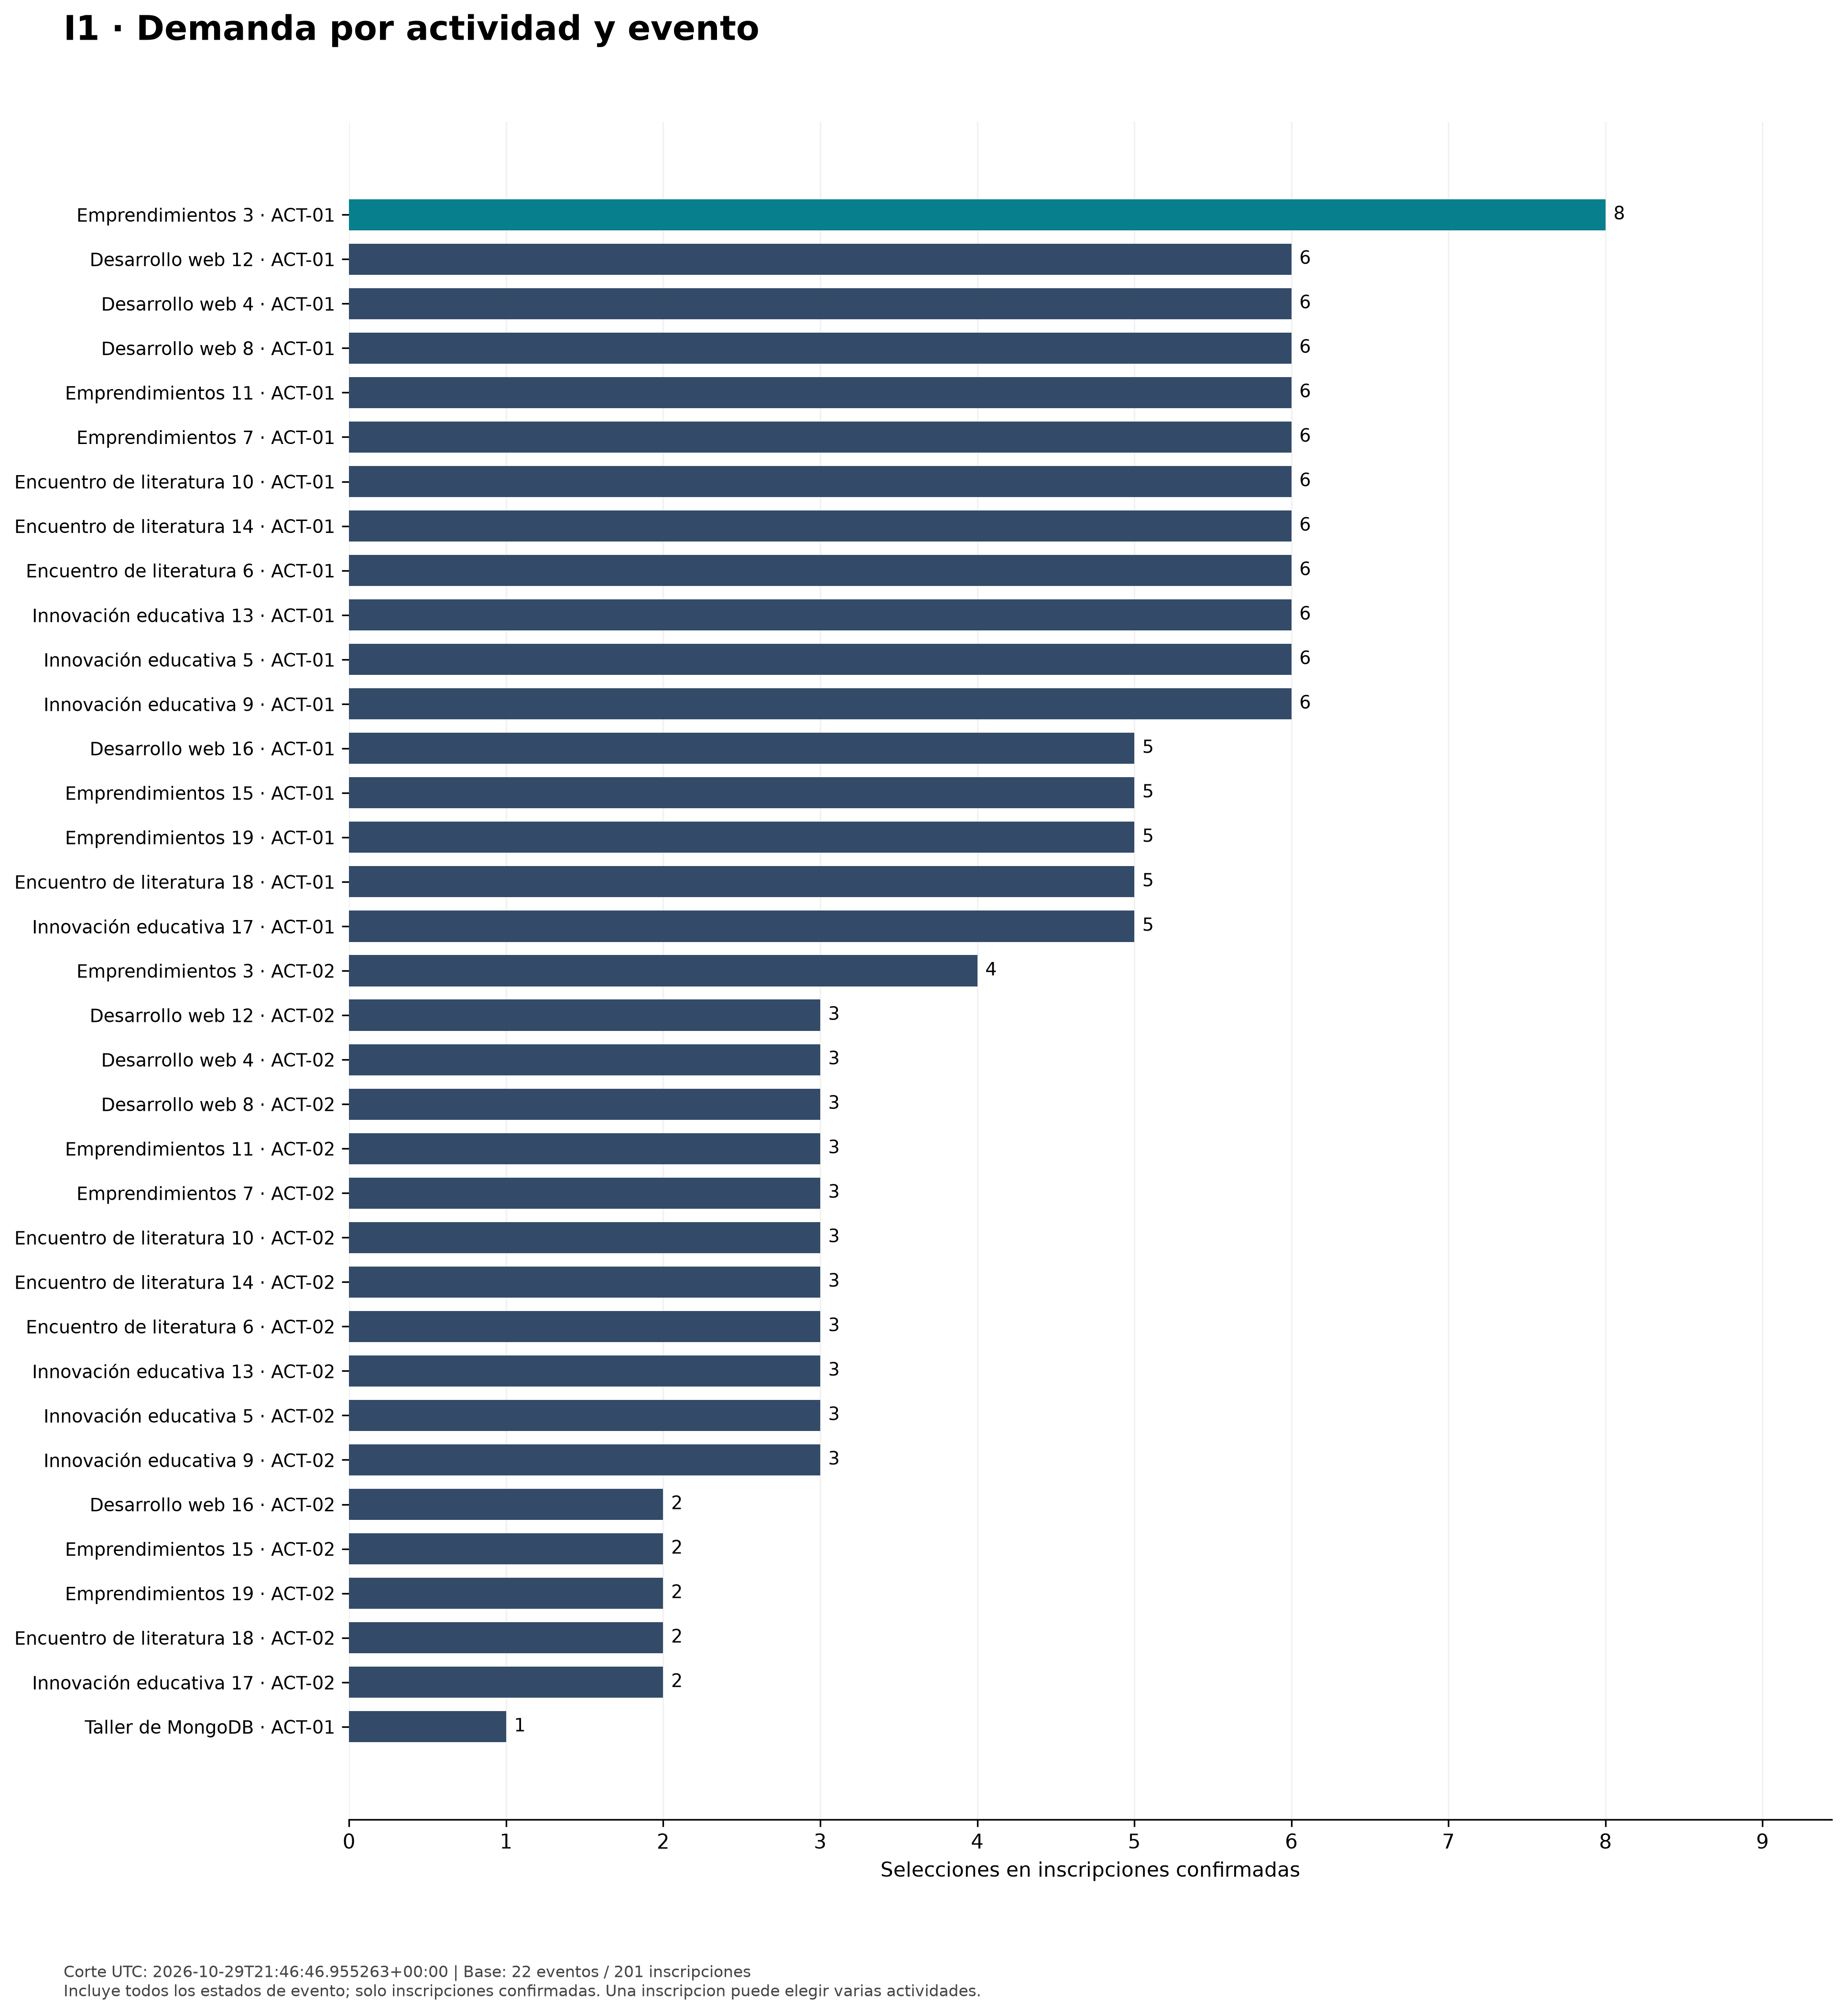

# I1. Demanda por actividad

Corte de ejecucion UTC: 2026-10-29T21:46:46.955263+00:00.
Base consultada: 22 eventos y 201 inscripciones.

Hay **152 inscripciones confirmadas**, de las cuales **52** no seleccionaron actividades.
Se registran **147 selecciones** distribuidas en **35 pares de evento y actividad**.

La mayor demanda observada es de **8 selecciones**:
- Emprendimientos 3 — ACT-01: Emprendimientos práctico.

## Interpretacion y limites

La unidad es una seleccion por evento y actividad. No son asistentes efectivos ni personas unicas entre eventos.
Una inscripcion puede elegir varias actividades: la suma de selecciones puede superar el numero de inscriptos que eligieron alguna.
Se agrupa por evento y codigo, porque ACT-01 de un evento no es la misma actividad que ACT-01 de otro.
I1 filtra estado de inscripcion, no estado del evento. Puede incluir demanda historica de un evento cancelado si conserva confirmadas.
Las actividades sin selecciones no aparecen como grupos; el grafico muestra todos los grupos con demanda positiva, sin recortar a un top.
Estos datos ficticios permiten demostrar la tecnica; no justifican inferencias sobre demanda real del mercado.
La inscripcion cancelada de la demo queda excluida por el filtro; los eventos sin inscripciones no aportan selecciones.


In [3]:
import sys
from IPython.display import display, Image, Markdown

carpeta_analisis = str(raiz / "analisis")
if carpeta_analisis not in sys.path:
    sys.path.insert(0, carpeta_analisis)
from i1_demanda import obtener_i1, exportar_i1

tabla_i1, corte_i1 = obtener_i1(raiz)
display(tabla_i1)
print(corte_i1)
destino_i1 = exportar_i1(tabla_i1, corte_i1, raiz)
print("Resultados:", destino_i1)
display(Image(filename=str(destino_i1 / "i1_demanda.png")))
display(Markdown((destino_i1 / "i1_interpretacion.md").read_text(encoding="utf-8")))


## I2. Ocupacion por evento

Solo publicados y finalizados. Calculo: 100 * confirmadas / capacidad_total.
Muestra tabla completa, ocupacion global ponderada y promedio simple (distintos).
No genera un grafico adicional: los dos graficos previstos son I1 e I3.


In [4]:
import sys
from IPython.display import display, Markdown

carpeta_analisis = str(raiz / "analisis")
if carpeta_analisis not in sys.path:
    sys.path.insert(0, carpeta_analisis)
from i2_ocupacion import obtener_i2, exportar_i2

tabla_i2, corte_i2 = obtener_i2(raiz)
display(tabla_i2)
print(corte_i2)
destino_i2 = exportar_i2(tabla_i2, corte_i2, raiz)
print("Resultados:", destino_i2)
display(Markdown((destino_i2 / "i2_interpretacion.md").read_text(encoding="utf-8")))


,evento_id,evento,estado_evento,capacidad_total,inscripciones_confirmadas,vacantes_disponibles,ocupacion_porcentaje
0,720000000000000000000003,Emprendimientos 3,publicado,12,12,0,100.00
1,720000000000000000000004,Desarrollo web 4,publicado,28,9,19,32.14
2,720000000000000000000005,Innovación educativa 5,publicado,30,9,21,30.00
3,720000000000000000000006,Encuentro de literatura 6,publicado,32,9,23,28.12
4,720000000000000000000007,Emprendimientos 7,publicado,34,9,25,26.47
5,720000000000000000000008,Desarrollo web 8,publicado,36,9,27,25.00
6,720000000000000000000009,Innovación educativa 9,publicado,38,9,29,23.68
7,720000000000000000000010,Encuentro de literatura 10,publicado,40,9,31,22.50
8,720000000000000000000011,Emprendimientos 11,publicado,42,9,33,21.43
9,720000000000000000000012,Desarrollo web 12,publicado,44,9,35,20.45


{'fecha_ejecucion_utc': '2026-10-29T21:46:48.400940+00:00', 'base': 'gestion_eventos', 'eventos': 22, 'inscripciones': 201, 'inscripciones_confirmadas_totales': 152, 'eventos_incluidos': 17, 'capacidad_incluida': 682, 'confirmadas_en_eventos_incluidos': 143, 'vacantes_en_eventos_incluidos': 539, 'ocupacion_global_ponderada_porcentaje': '20.97', 'promedio_simple_por_evento_porcentaje': '25.12', 'eventos_excluidos': 5, 'estados_incluidos': ['publicado', 'finalizado'], 'unidad': 'porcentaje de capacidad por evento', 'formula': '100 * inscripciones_confirmadas / capacidad_total', 'politica_demo': 'base actual; excluir borradores y cancelados por estado, no por titulo'}
Resultados: C:\Users\nicoa\proyecto-eventos-reorganizado\analisis\resultados\I2_20261029T214648_425391Z


# I2. Ocupacion por evento

Corte UTC: 2026-10-29T21:46:48.400940+00:00.
Base consultada: 22 eventos y 201 inscripciones.

Se incluyen **17 eventos publicados o finalizados** y se excluyen **5** borradores/cancelados.
En los eventos incluidos hay **143 inscripciones confirmadas** sobre **682 lugares** de capacidad.

Ocupacion global ponderada por capacidad: **20.97%**.
Promedio simple de porcentajes por evento: **25.12%**.

No son el mismo calculo: el global divide las sumas; el promedio simple da igual peso a cada evento.

- Mayor porcentaje mostrado: **Emprendimientos 3**, 100.00% (12/12).

## Interpretacion y limites

Cada porcentaje es 100 * confirmadas / capacidad_total. Las inscripciones canceladas no cuentan.
En un evento publicado mide cupo reservado; en uno finalizado describe el registro final, no asistencia efectiva.
El denominador no son las vacantes ni el numero total de inscripciones de la base.
I1 e I2 usan poblaciones distintas: I1 puede incluir confirmadas de eventos cancelados; I2 excluye esos eventos.
No se eliminan registros de demo: sus estados determinan si participan.
Los porcentajes se muestran con dos decimales; las agregaciones se calculan antes de redondear.
La tabla muestra todos los eventos elegibles, incluidos los de ocupacion cero.
El poblado es ficticio: no se generalizan estos porcentajes a una demanda real del mercado.


## I3. Recaudacion bruta registrada por mes

Suma Decimal por mes UTC de fecha_inscripcion; incluye canceladas.
Muestra tabla, grafico de lineas e interpretacion y guarda corte y archivos locales.
No descuenta devoluciones ni representa ingreso neto. No es una proyeccion.


,mes_utc,importe_bruto,cantidad_inscripciones,inscripciones_canceladas,importe_canceladas,mes_sin_registros
0,2026-08,234000.00,55,15,52000.00,False
1,2026-09,0.00,1,0,0,False
2,2026-10,555000.00,145,34,92000.00,False


{'fecha_ejecucion_utc': '2026-10-29T21:46:48.468069+00:00', 'base': 'gestion_eventos', 'eventos': 22, 'inscripciones': 201, 'meses_mostrados': 3, 'meses_sin_registros_rellenados': 0, 'inscripciones_en_tabla': 201, 'inscripciones_canceladas_en_tabla': 49, 'importe_bruto_total': '789000.00', 'importe_registrado_canceladas': '144000.00', 'unidad': 'importe monetario registrado, sin conversion de moneda', 'regla': 'sumar importe_abonado por mes UTC de fecha_inscripcion; incluir todos los estados', 'politica_demo': 'base actual, sin excluir por titulo ni recargar datos', 'meses_vacios': 'rellenar con cero solo entre el primer y ultimo mes observados'}


Resultados: C:\Users\nicoa\proyecto-eventos-reorganizado\analisis\resultados\I3_20261029T214648_485839Z


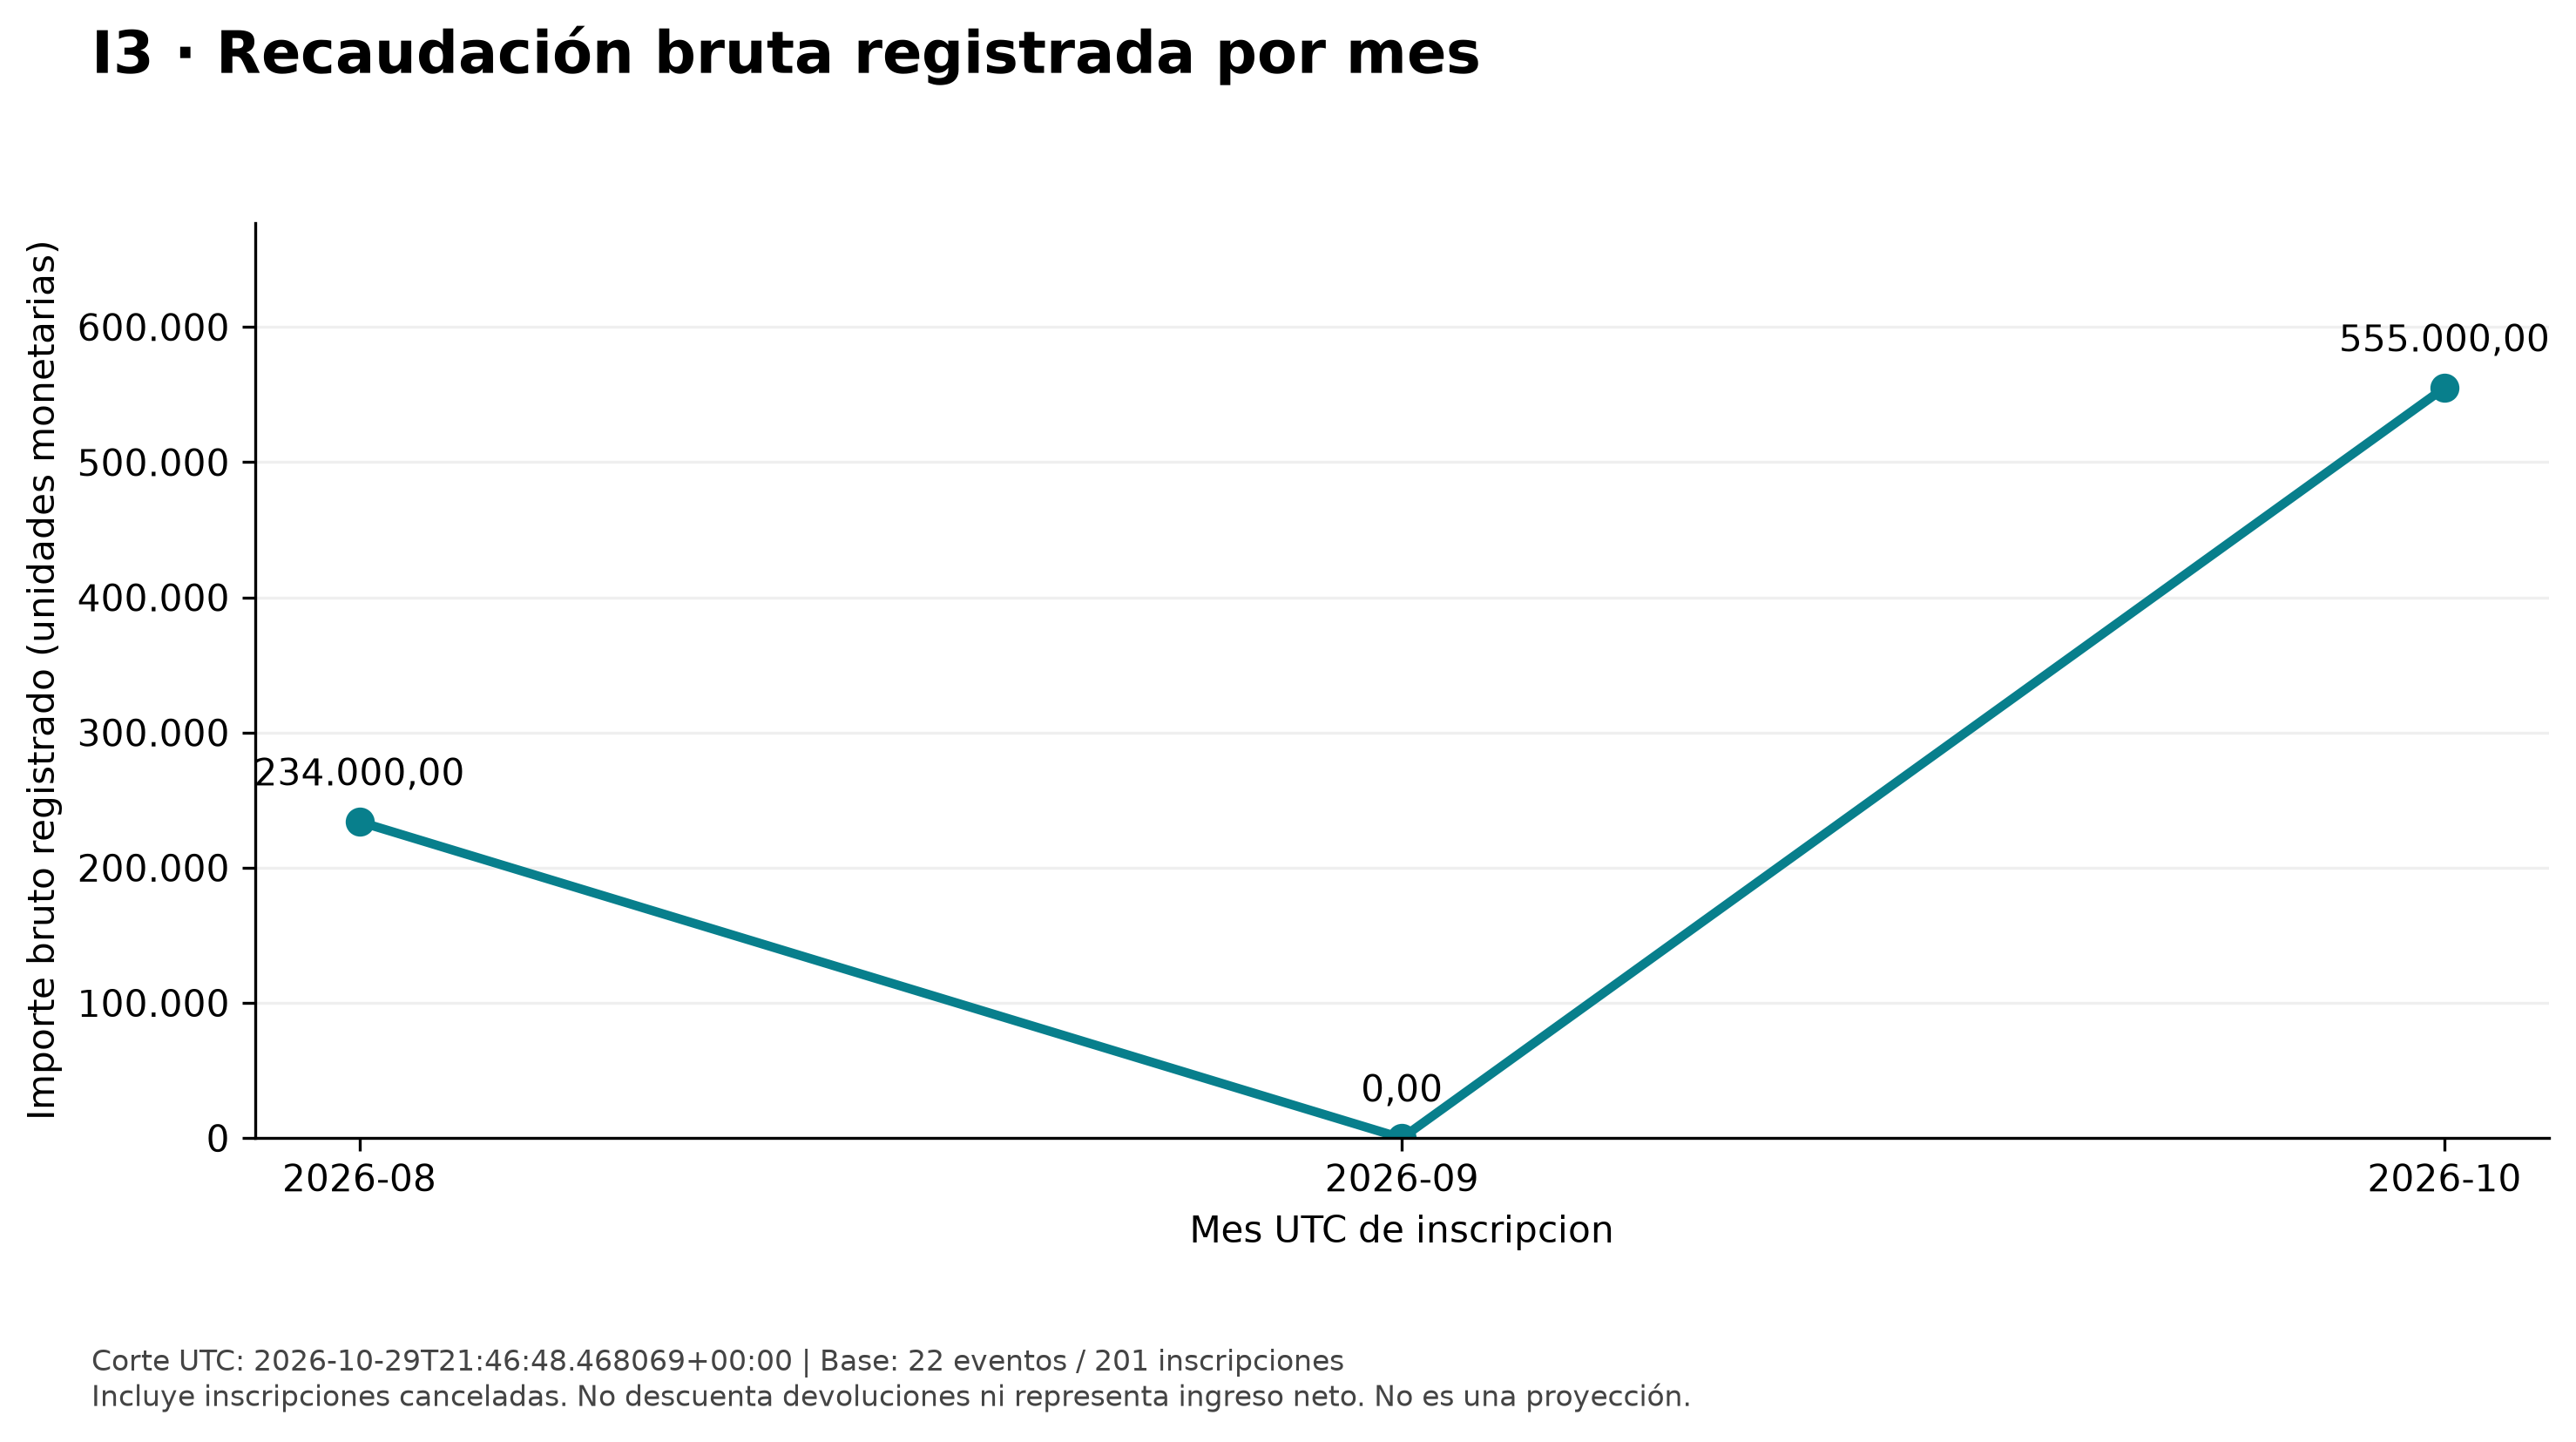

# I3. Recaudacion bruta registrada por mes

Corte UTC: 2026-10-29T21:46:48.468069+00:00.
Base: 22 eventos y 201 inscripciones.

Importe bruto registrado: **789000.00** en **3 meses mostrados.
Incluye **49 inscripciones canceladas**, que registran **144000.00**. No se restan estos importes.

El mayor importe mensual corresponde a **2026-10**, con **555000.00**.
- 2026-08: 234000.00; 55 inscripciones (15 canceladas).
- 2026-09: 0.00; 1 inscripciones (0 canceladas).
- 2026-10: 555000.00; 145 inscripciones (34 canceladas).

## Interpretacion y limites

Se agrupa por fecha de inscripcion, no por fecha del evento. La zona horaria es UTC.
Es recaudacion bruta registrada: no se deducen devoluciones, comisiones, impuestos o costos; no representa ganancia ni ingreso neto.
Un mes con importe cero puede contener inscripciones gratuitas o invitaciones; no implica necesariamente ausencia de inscripciones.
Solo se rellenan meses intermedios sin registros con cero, identificados en la tabla; no se agregan meses externos al periodo observado.
El grafico conecta totales mensuales observados: no estima valores diarios ni proyecta periodos futuros.
Las diferencias del poblado ficticio dependen de las fechas, precios e invitaciones generados; no se interpretan como tendencia del mercado.
La demo gratuita y cancelada se incluye en el conteo mensual, aunque su importe es cero.


In [5]:
import sys
from IPython.display import display, Image, Markdown

carpeta_analisis = str(raiz / "analisis")
if carpeta_analisis not in sys.path:
    sys.path.insert(0, carpeta_analisis)
from i3_recaudacion import obtener_i3, exportar_i3

tabla_i3, corte_i3 = obtener_i3(raiz)
display(tabla_i3)
print(corte_i3)
destino_i3 = exportar_i3(tabla_i3, corte_i3, raiz)
print("Resultados:", destino_i3)
display(Image(filename=str(destino_i3 / "i3_recaudacion.png")))
display(Markdown((destino_i3 / "i3_interpretacion.md").read_text(encoding="utf-8")))


## Resultados e interpretacion

Los resultados de esta ejecucion son los mostrados por las celdas anteriores y sus archivos de corte.
Como referencia, las ejecuciones por script del 29/10/2026 (base 22/201) dieron:

- **I1:** 152 confirmadas, 52 sin actividades, 147 selecciones en 35 pares evento/actividad. Emprendimientos 3 / ACT-01 tuvo 8 selecciones.
- **I2:** 17 eventos elegibles, 143 confirmadas sobre capacidad 682, 539 vacantes. Ocupacion global 20,97%; promedio simple 25,12%.
- **I3:** agosto 234000, septiembre 0 y octubre 555000; bruto total 789000. Incluye 49 canceladas con importe registrado 144000.

Estos valores son referencias verificadas en ejecuciones previas, no sustituyen las salidas actuales.
I1 e I2 tienen poblaciones distintas: I2 excluye eventos cancelados, mientras I1 conserva su demanda historica si sus inscripciones siguen confirmadas.
La suma de selecciones de I1 no es cantidad de asistentes. La ocupacion de I2 mide reservas, no asistencia efectiva.
I3 agrupa por fecha de inscripcion UTC y no descuenta devoluciones, impuestos o costos: no es ingreso neto.
Septiembre tuvo una inscripcion de importe cero; no fue un mes sin inscripciones.

El poblado es ficticio y reducido. No se infieren tendencias de mercado ni se extrapolan los resultados.
Las dos figuras son barras para I1 y lineas para I3. Los archivos PNG/SVG de cada indicador son formatos de una misma figura.


In [6]:
# Ejecutar al terminar de trabajar con el notebook.
cliente.close()
